# Dự đoán cường độ carbon ngành điện bằng Machine Learning

**Dữ liệu:** Our World in Data (OWID) / Ember, giai đoạn 2000–2025  
**Biến đích:** cường độ phát thải vòng đời của điện, gCO₂e/kWh  
**Mô hình:** Linear Regression, Random Forest, XGBoost

Mục tiêu là đánh giá khả năng ước lượng cường độ carbon từ cơ cấu nguồn điện và
các đặc trưng hệ thống điện. Dữ liệu được chia hoàn toàn theo thời gian để tránh
đưa quan sát tương lai vào quá trình huấn luyện hoặc chọn siêu tham số.

Notebook này dùng chung mô-đun `src/carbon_intensity_workflow.py` với lệnh chạy
tự động. Do đó bảng, hình và paper đều truy xuất cùng một kết quả thực nghiệm.

## 1. Thiết kế thực nghiệm đã khóa trước khi huấn luyện

- Train: 2000–2018.
- Validation: 2019–2021, dùng để chọn siêu tham số theo RMSE.
- Test: 2022–2025, chỉ đánh giá sau khi chọn cấu hình; năm 2025 là dữ liệu một
  phần nên được nêu rõ trong giới hạn nghiên cứu.
- Chỉ giữ mã quốc gia ISO-3; loại các tổng hợp vùng/thế giới.
- Một hàng cần có ít nhất 8/11 đặc trưng nguồn trước khi impute.
- Median imputation được fit trong từng pipeline, chỉ từ tập huấn luyện tương ứng.
- Không dùng `carbon_intensity_elec`, tổng phát thải điện, hay biến được suy ra
  trực tiếp từ biến đích làm đầu vào.
- Random seed cố định: 42.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image

ROOT = Path.cwd()
if not (ROOT / "src" / "carbon_intensity_workflow.py").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import carbon_intensity_workflow as wf

print("Repository root:", ROOT)
print("Random seed:", wf.SEED)

Repository root: D:\OneDrive - University Of Industry and Trade\kmeans-owid-country-development\kmeans-owid-country-development
Random seed: 42


## 2. Tải và kiểm tra provenance

Nếu snapshot chưa tồn tại, cell dưới tải trực tiếp CSV/metadata chính thức. Muốn
làm mới dữ liệu ở một lần chạy khác, đổi `force=False` thành `force=True`; việc
đó có thể làm thay đổi kết quả vì OWID cập nhật dữ liệu định kỳ.

In [2]:
downloaded = wf.download_sources(force=False)
provenance = wf.audit_sources()
print("Downloaded in this run:", downloaded or "none; using versioned local snapshots")
display(pd.DataFrame({
    "energy_shape": [provenance["energy_shape"]],
    "energy_year_range": [provenance["energy_year_range"]],
    "target_shape": [provenance["target_shape"]],
    "target_year_range": [provenance["target_year_range"]],
    "target_unit": [provenance["target_unit"]],
}))
display(pd.DataFrame(provenance["files"]).T[["bytes", "sha256", "modified_utc"]])

Downloaded in this run: none; using versioned local snapshots


,energy_shape,energy_year_range,target_shape,target_year_range,target_unit
0,"[23377, 130]","[1900, 2025]","[6332, 4]","[1990, 2025]",gCO2e/kWh (lifecycle)


,bytes,sha256,modified_utc
owid-energy-data.csv,15926881,77b3db513f02f5fffb69fe02832907ce70b01d3906fc2c...,2026-09-25T16:14:45.553638+00:00
owid-energy-codebook.csv,45793,3cc9b7db0d921496e2988568ce3aee5ed41f50431dd234...,2026-09-25T16:14:46.430562+00:00
owid-electricity-carbon-intensity.csv,166063,96f8a3dfd845f0cfea6bdd16274fe7a97b790c20237ad7...,2026-09-25T16:14:47.915962+00:00
owid-electricity-carbon-intensity.metadata.json,1747,ce8eff46eb3921af1144edbeaf0f881193873ad7bd8b0e...,2026-09-25T16:14:49.472533+00:00


## 3. Tiền xử lý, kiểm tra missingness và chia theo thời gian

In [3]:
model_data, audit = wf.prepare_dataset()
print(json.dumps(audit, ensure_ascii=False, indent=2))
display(pd.read_csv(wf.TABLE_DIR / "split_summary.csv"))
display(pd.read_csv(wf.TABLE_DIR / "feature_missingness.csv"))
display(model_data.head())

{
  "rows_before_feature_rule": 5690,
  "rows_after_feature_rule": 5281,
  "excluded_for_sparse_features": 409,
  "countries": 212,
  "year_min": 2000,
  "year_max": 2025,
  "duplicate_country_year": 0,
  "split_rows": {
    "train": 3944,
    "validation": 632,
    "test": 705
  }
}


,split,rows,countries,year_min,year_max,target_mean,target_std
0,train,3944,210,2000,2018,483.972984,249.991803
1,validation,632,211,2019,2021,456.987484,244.013775
2,test,705,211,2022,2025,425.404170,243.479781


,feature,missing_percent
0,coal_share_elec,0.378716
1,gas_share_elec,1.988260
2,oil_share_elec,0.000000
3,hydro_share_elec,1.439121
4,nuclear_share_elec,1.723158
5,wind_share_elec,2.707820
6,solar_share_elec,0.094679
7,biofuel_share_elec,0.056807
8,other_renewables_share_elec,0.056807
9,net_elec_imports_share_demand,0.000000


,country,iso_code,year,split,carbon_intensity_gco2e_kwh,available_feature_count,coal_share_elec,gas_share_elec,oil_share_elec,hydro_share_elec,nuclear_share_elec,wind_share_elec,solar_share_elec,biofuel_share_elec,other_renewables_share_elec,net_elec_imports_share_demand,log_per_capita_electricity
0,Aruba,ABW,2000,train,653.85,11,0.0,0.0,100.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,9.081092
1,Afghanistan,AFG,2000,train,250.00,11,0.0,0.0,35.416668,64.583336,0.0,0.0,0.0,0.0,0.0,15.789474,3.212641
2,Angola,AGO,2000,train,256.94,11,0.0,0.0,36.805553,63.194443,0.0,0.0,0.0,0.0,0.0,0.000000,4.498887
3,Albania,ALB,2000,train,48.63,11,0.0,0.0,3.805497,96.194504,0.0,0.0,0.0,0.0,0.0,17.452007,7.309834
4,United Arab Emirates,ARE,2000,train,676.77,10,0.0,100.0,0.000000,NaN,0.0,0.0,0.0,0.0,0.0,0.000000,9.344293


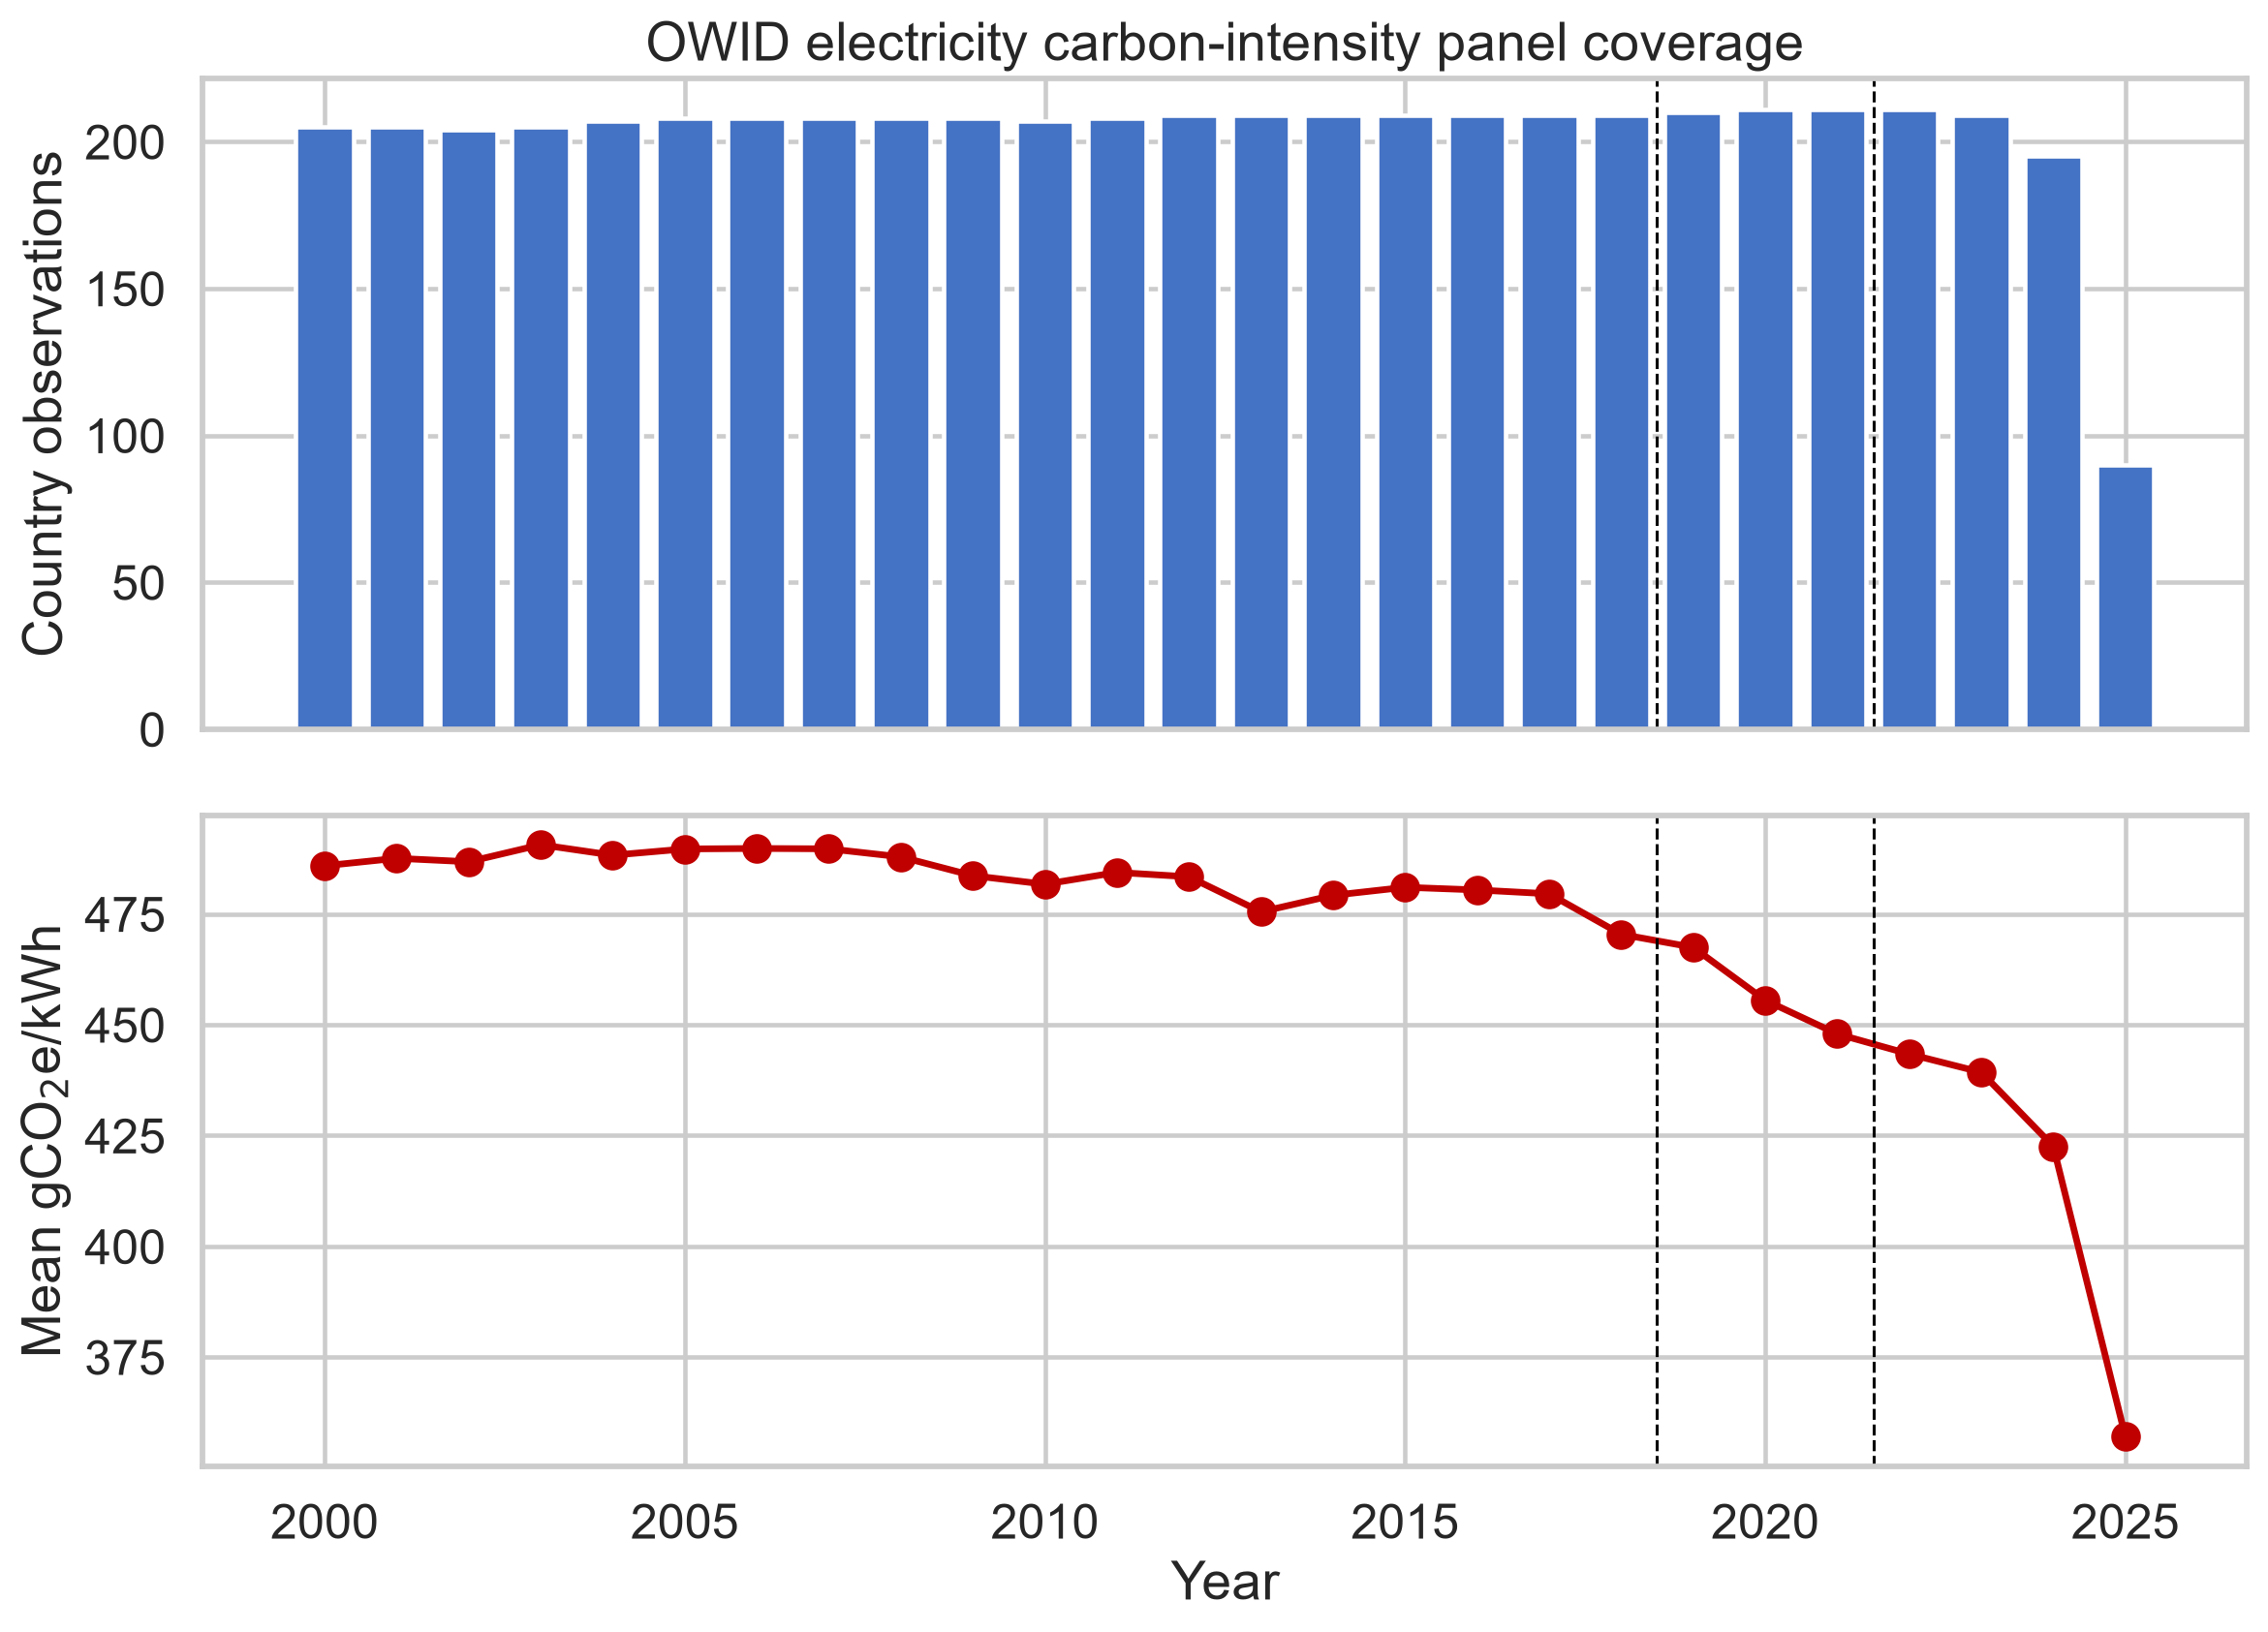

In [4]:
display(Image(filename=str(wf.FIGURE_DIR / "dataset_coverage_and_trend.png")))

## 4. Huấn luyện, chọn siêu tham số và đánh giá test

Linear Regression đóng vai trò baseline tuyến tính. Random Forest và XGBoost
được thử trên lưới nhỏ đã định nghĩa trong mã. Mỗi cấu hình chỉ nhìn train khi
đánh giá validation. Sau khi chọn cấu hình tốt nhất cho từng họ mô hình, pipeline
được fit lại trên train+validation rồi đánh giá đúng một lần trên test.

In [5]:
summary = wf.train_evaluate_and_report(model_data, audit)
print(json.dumps(summary, ensure_ascii=False, indent=2))
metrics = pd.read_csv(wf.TABLE_DIR / "model_metrics.csv")
display(metrics[["split", "model", "n", "mae", "rmse", "r2", "parameters"]])

{
  "best_test_model": "XGBoost",
  "best_test_mae": 24.2476838174103,
  "best_test_rmse": 41.02615306120217,
  "best_test_r2": 0.9715676836194501,
  "test_rows": 705,
  "metrics_path": "D:\\OneDrive - University Of Industry and Trade\\kmeans-owid-country-development\\kmeans-owid-country-development\\outputs\\carbon_intensity\\tables\\model_metrics.csv",
  "paper_macros_path": "D:\\OneDrive - University Of Industry and Trade\\kmeans-owid-country-development\\kmeans-owid-country-development\\paper\\generated_results.tex"
}


,split,model,n,mae,rmse,r2,parameters
0,Validation (2019-2021),Linear Regression,632,43.600220,81.827675,0.887369,{}
1,Validation (2019-2021),Random Forest,632,29.974342,48.782282,0.959970,"{""max_depth"": null, ""max_features"": 0.8, ""min_..."
2,Validation (2019-2021),XGBoost,632,25.815059,48.244675,0.960848,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."
3,Test (2022-2025),Linear Regression,705,43.541133,77.833085,0.897666,{}
4,Test (2022-2025),Random Forest,705,29.768985,47.141183,0.962460,"{""max_depth"": null, ""max_features"": 0.8, ""min_..."
5,Test (2022-2025),XGBoost,705,24.247684,41.026153,0.971568,"{""colsample_bytree"": 0.9, ""learning_rate"": 0.0..."


## 5. Biểu đồ kết quả và phân tích sai số

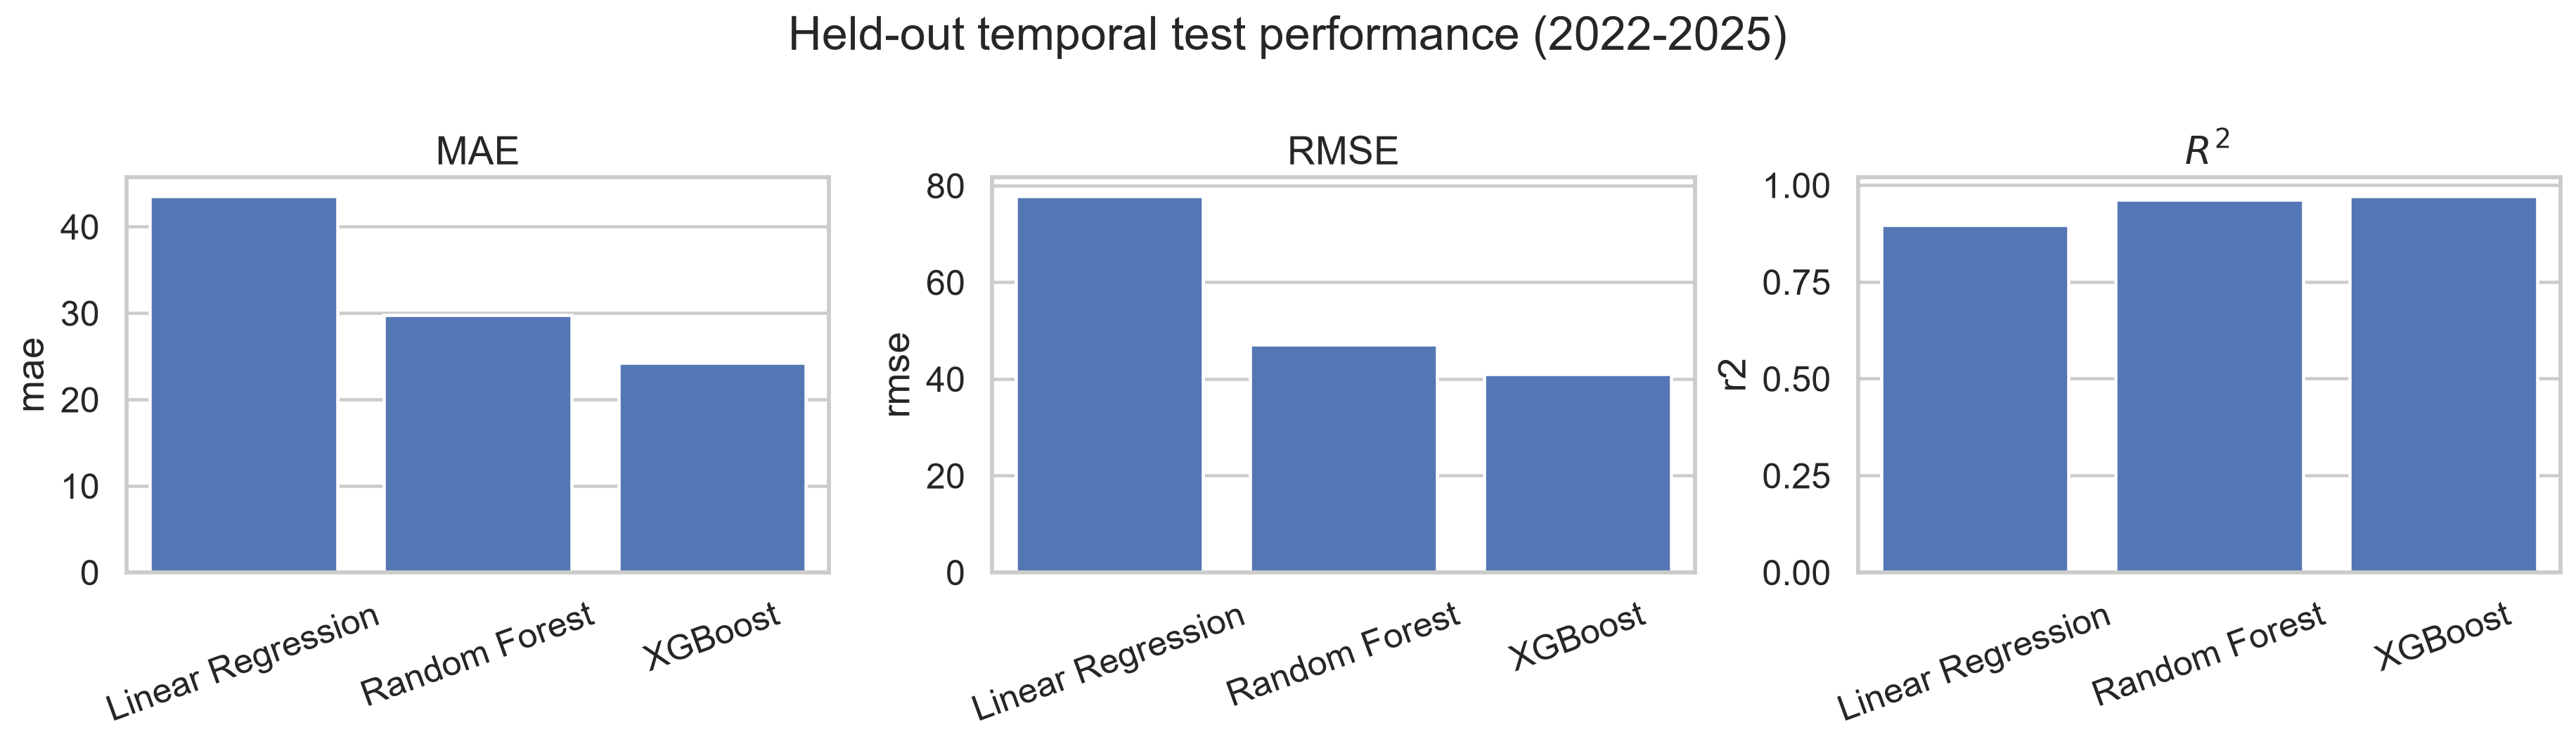

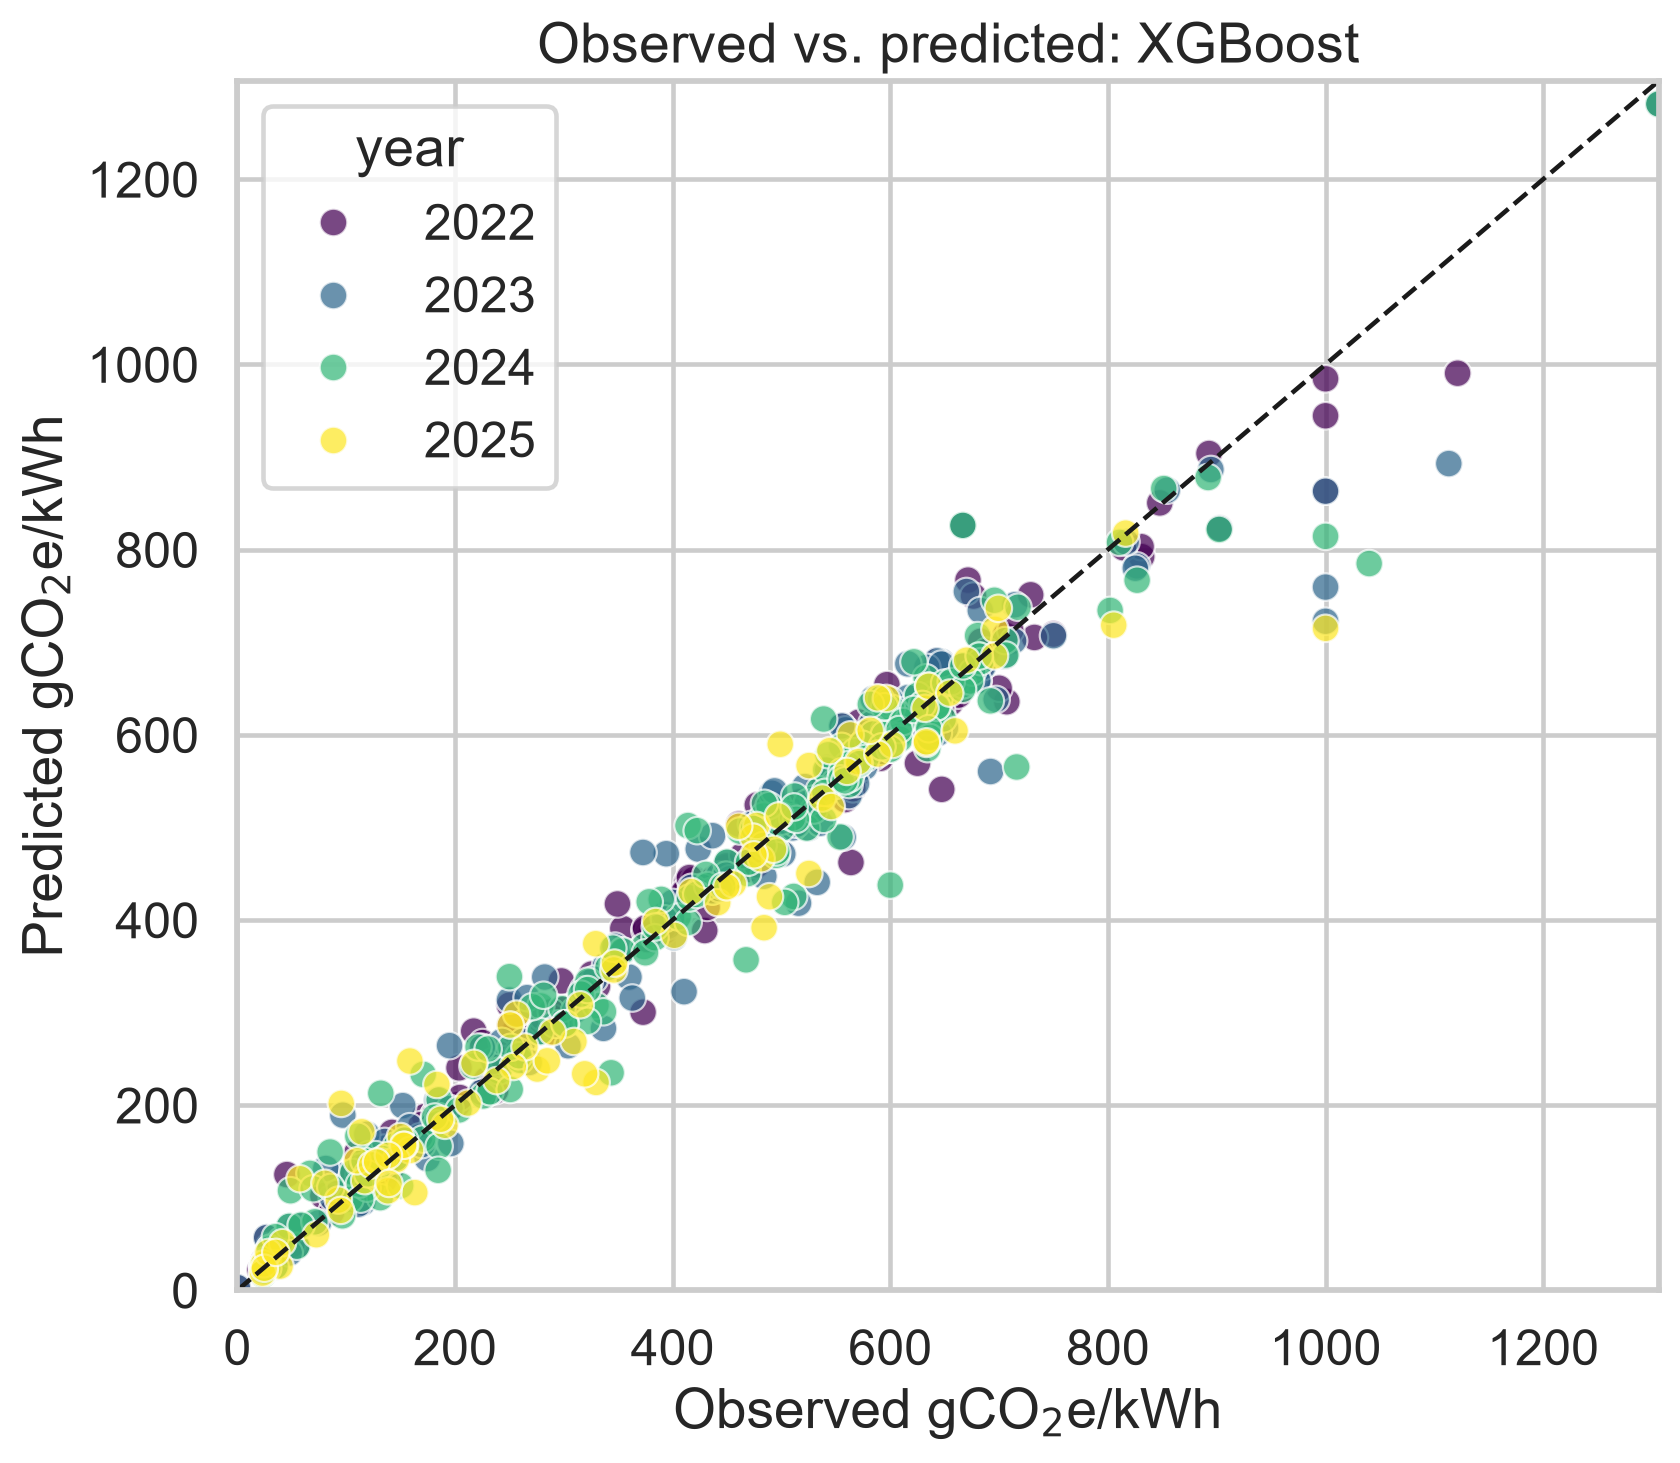

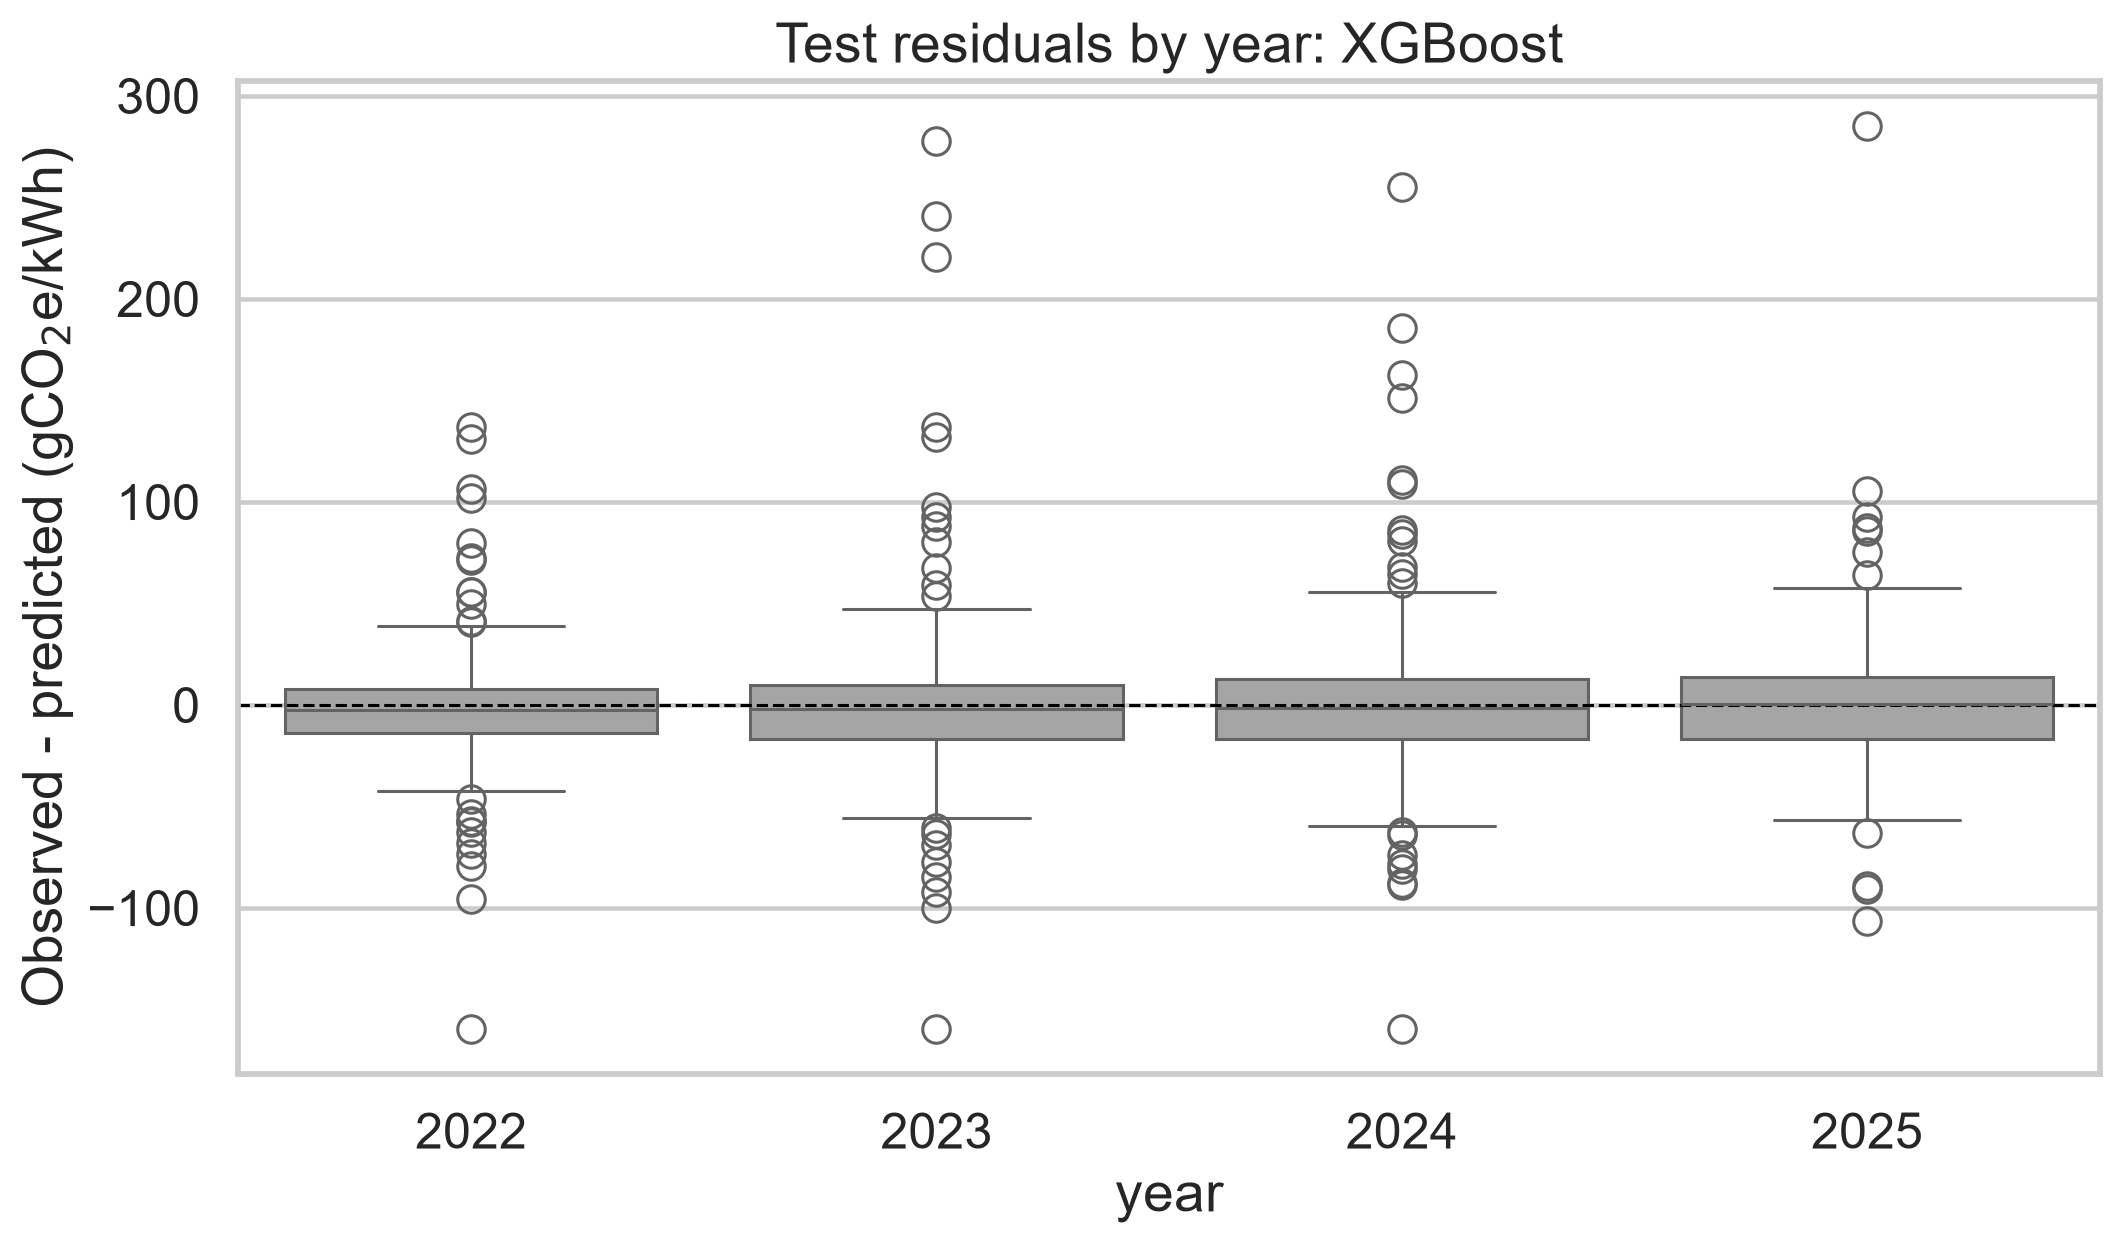

,year,model,n,mae,rmse,r2
0,2022,Linear Regression,211,43.615755,80.781245,0.890602
1,2022,Random Forest,211,22.214905,37.488544,0.976439
2,2022,XGBoost,211,19.141518,30.948942,0.983942
3,2023,Linear Regression,209,43.914085,80.559203,0.892171
4,2023,Random Forest,209,29.653827,47.779368,0.962070
5,2023,XGBoost,209,25.763159,45.023657,0.966319
6,2024,Linear Regression,195,42.623487,76.127066,0.900943
7,2024,Random Forest,195,31.912718,48.156671,0.960361
8,2024,XGBoost,195,25.696258,42.712785,0.968817
9,2025,Linear Regression,90,44.488345,67.290765,0.912003


In [6]:
for filename in [
    "model_comparison_test.png",
    "actual_vs_predicted_best.png",
    "residuals_by_year_best.png",
]:
    display(Image(filename=str(wf.FIGURE_DIR / filename)))

display(pd.read_csv(wf.TABLE_DIR / "test_metrics_by_year.csv"))

## 6. Feature importance và SHAP

Native importance của cây phản ánh cách mô hình sử dụng biến; SHAP mô tả độ lớn
và chiều đóng góp cục bộ của từng đặc trưng cho dự đoán XGBoost. Đây là liên hệ
dự báo, không phải bằng chứng nhân quả.

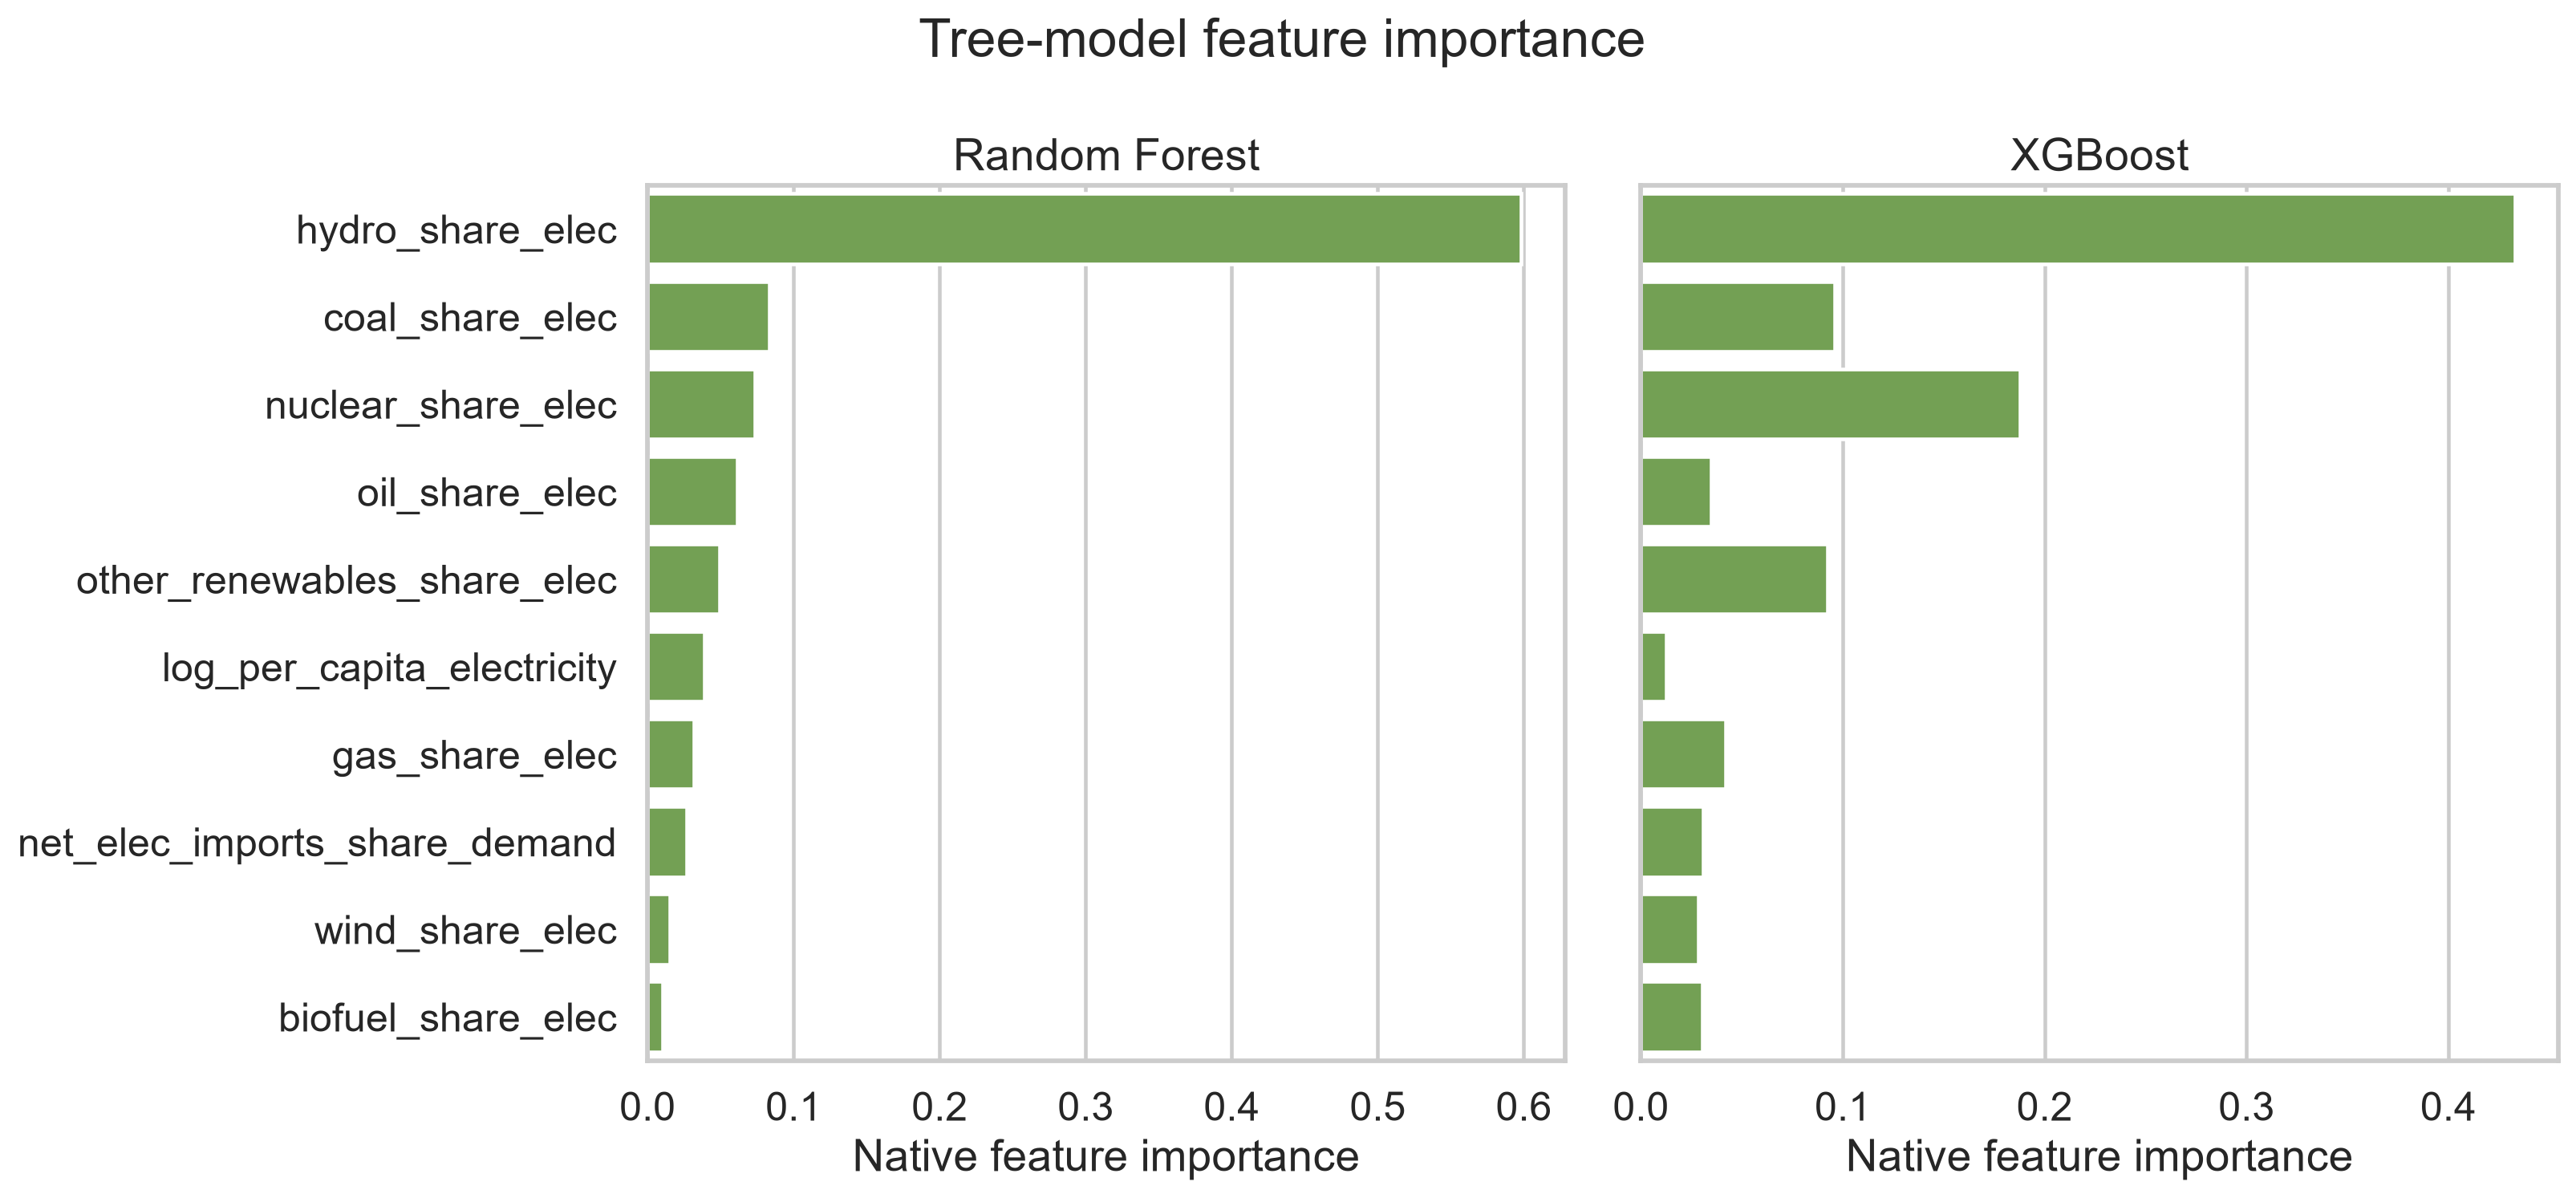

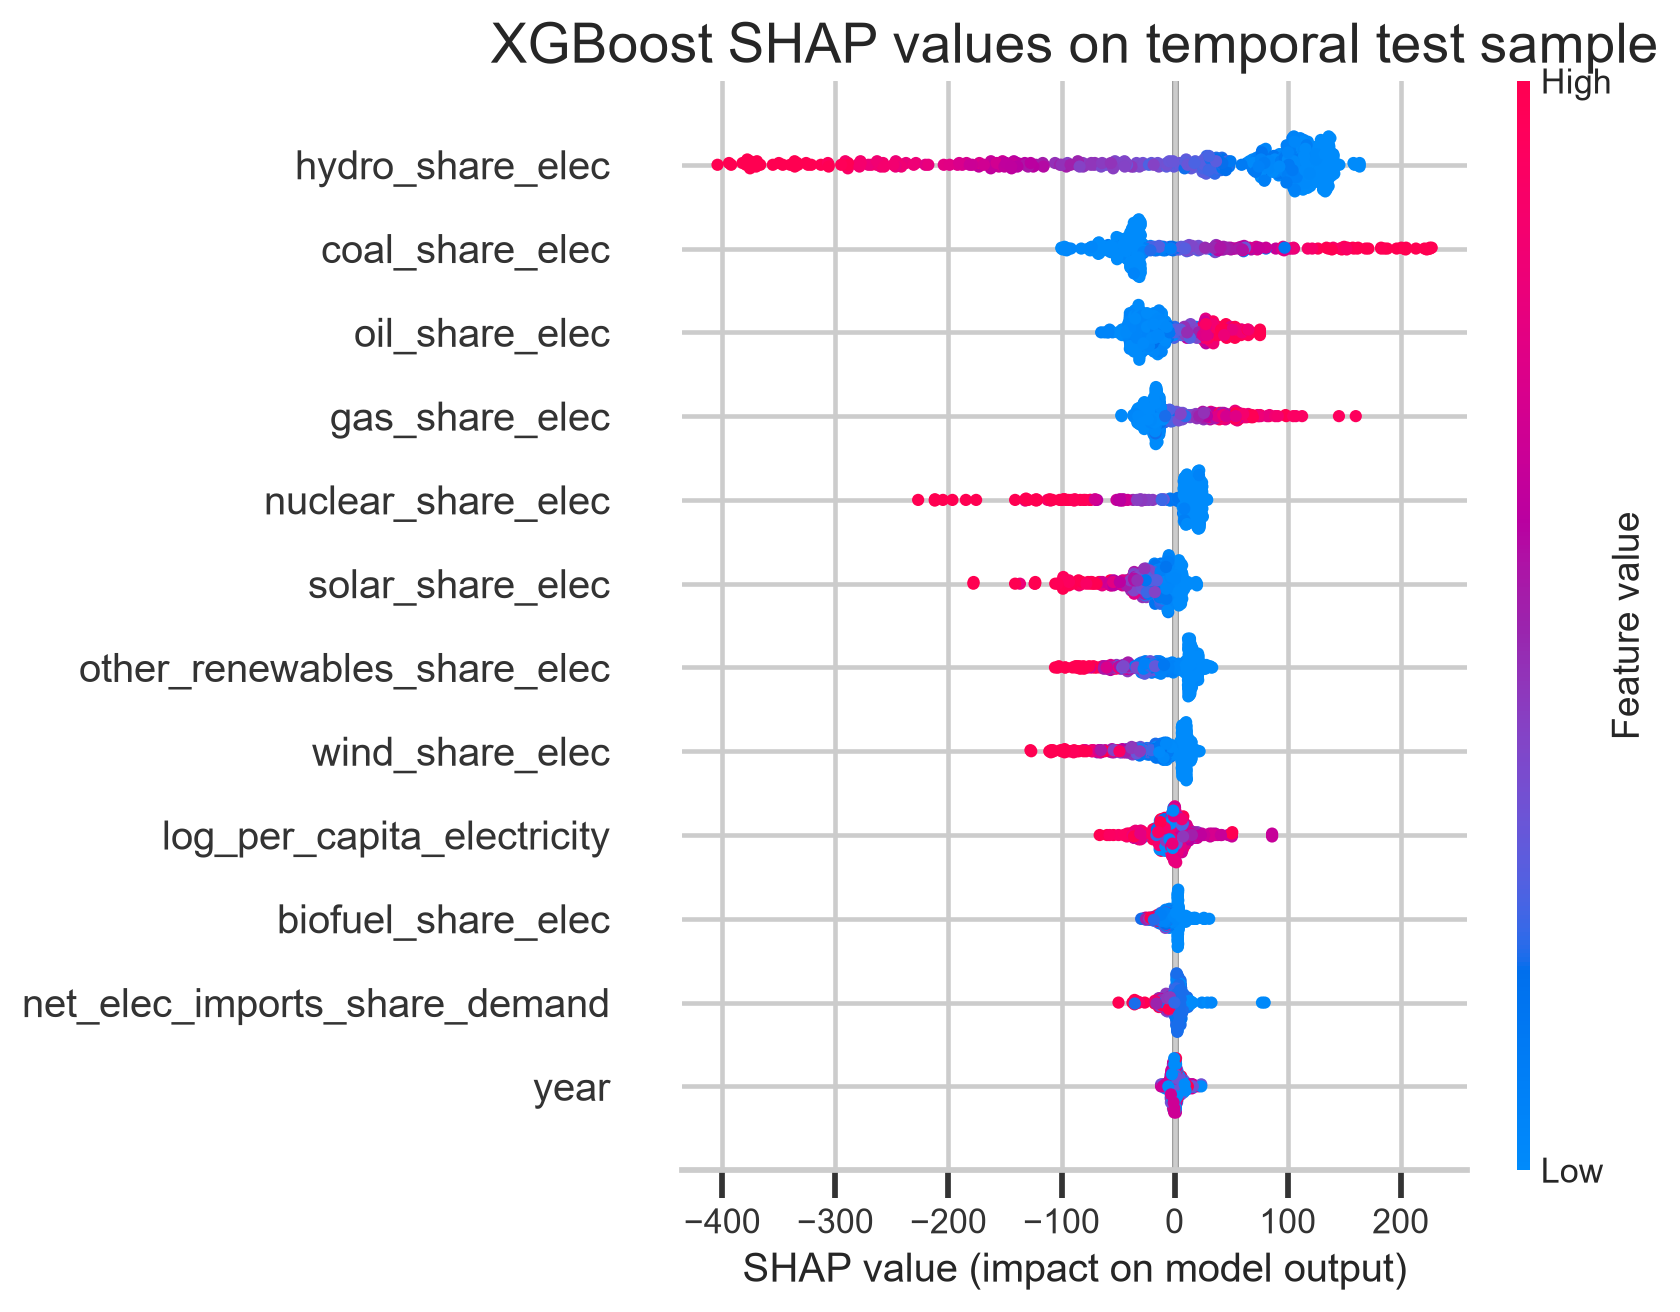

,feature,mean_abs_shap
0,hydro_share_elec,123.467250
1,coal_share_elec,51.048035
2,oil_share_elec,27.051262
3,gas_share_elec,25.851290
4,nuclear_share_elec,24.854958
5,solar_share_elec,24.211850
6,other_renewables_share_elec,23.101704
7,wind_share_elec,22.433601
8,log_per_capita_electricity,11.564614
9,biofuel_share_elec,7.336984


,feature,permutation_importance_mean,permutation_importance_std
0,hydro_share_elec,167.641592,4.082207
1,coal_share_elec,78.589039,2.711574
2,gas_share_elec,47.675864,1.996423
3,nuclear_share_elec,38.541600,3.195923
4,oil_share_elec,37.639426,1.328408
5,solar_share_elec,25.664149,1.795566
6,other_renewables_share_elec,25.349605,1.379354
7,wind_share_elec,24.981555,1.430190
8,net_elec_imports_share_demand,18.987524,1.984659
9,log_per_capita_electricity,18.807757,1.720339


In [7]:
display(Image(filename=str(wf.FIGURE_DIR / "tree_feature_importance.png")))
display(Image(filename=str(wf.FIGURE_DIR / "xgboost_shap_beeswarm.png")))
display(pd.read_csv(wf.TABLE_DIR / "xgboost_shap_importance.csv").head(12))
display(pd.read_csv(wf.TABLE_DIR / "xgboost_permutation_importance.csv").head(12))

## 7. Artifact và khả năng tái lập

Kết quả máy đọc nằm trong `outputs/carbon_intensity/`; mô hình đã fit nằm trong
`models/`; các bảng LaTeX và macro được sinh tự động trong `paper/`. Paper không
chép tay metric mà dùng `\input{generated_results.tex}` và bảng tự sinh.

Giới hạn chính: năm 2025 chỉ phủ một phần quốc gia; các biến cùng năm phù hợp với
bài toán ước lượng/nowcasting, không nên diễn giải thành dự báo nhiều năm trong
tương lai; dữ liệu panel theo quốc gia tạo phụ thuộc lặp lại giữa các năm; SHAP
không xác lập quan hệ nhân quả.